# Quickstart: Norway field production (Sodir)

`ogprod` downloads public well- and field-level production data, normalizes
it into a canonical schema, and keeps it in a local Parquet store. Everything
goes through one object, `ogprod.Store`: **ingest → query → analyze**. This
notebook walks the loop on the smallest source: Norway's Sodir
`field_production_monthly` table — every field on the Norwegian shelf,
monthly, back to 1971, in a single ~2 MB CSV.

Run it from the `notebooks/` directory with the notebook dependencies:

```sh
uv run --group notebooks jupyter lab
```

In [1]:

import matplotlib.pyplot as plt

import ogprod

# Categorical palette in fixed slot order (colorblind-safe adjacency)
PALETTE = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "figure.figsize": (9, 4),
    "font.size": 11,
})

# The store lives in ~/.local/share/ogprod/store unless $OGPROD_STORE says otherwise.
db = ogprod.Store()
db

Store('/Users/mralbu/.local/share/ogprod/store')

In [2]:
ogprod.available()

['anp', 'argentina', 'sodir']

## Ingest into the store

`ingest` downloads the publisher's raw files, parses them into the canonical
schema, and upserts them into the store. The first ingest also brings in the
source's entities — here the field ring-fence polygons; later runs skip that
download unless you pass `refresh=True`. Upserts are keyed on
`(source, entity_id, period, product, field)`, so re-running is safe, and
re-running is also how you pick up the publisher's restatements.
From the shell, `just ingest sodir` does the same.

In [3]:
result = db.ingest("sodir")
print(result)

sodir: 142,275 production rows 1971-06..2026-07 in 56 partition(s); entities: 142


## Query the store

`db.production` reads canonical rows back with DuckDB filter pushdown
(source/year filters prune whole partitions before any data is read). The
frame is long-format: one row per `(entity, month, product)`, volumes
**always in m³**. Norway reports five products:

In [4]:
frame = db.production(source="sodir")
print(f"{len(frame):,} rows")
frame.groupby("product")["volume"].sum().map("{:.3g} m³".format)

142,275 rows


product
condensate    1.28e+08 m³
gas           3.34e+12 m³
ngl           5.08e+08 m³
oil           5.11e+09 m³
water         4.37e+09 m³
Name: volume, dtype: str

## Oil peaked around 2001 — gas has led since

Oil and gas volumes differ by two orders of magnitude, so they get two panels
with one axis each (never a dual-axis chart).

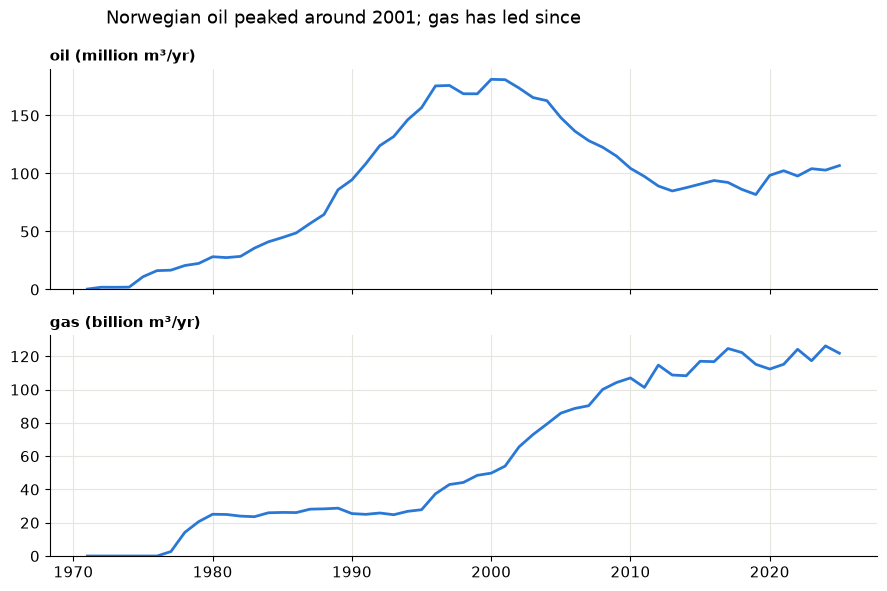

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, product, unit, scale in (
    (axes[0], "oil", "million m³/yr", 1e6),
    (axes[1], "gas", "billion m³/yr", 1e9),
):
    series = frame[frame["product"] == product]
    yearly = series.groupby(series["period"].dt.year)["volume"].sum() / scale
    yearly = yearly.iloc[:-1]  # drop the partial current year
    ax.plot(yearly.index, yearly.values)
    ax.set_title(f"{product} ({unit})", fontsize=11)
    ax.set_ylim(bottom=0)
fig.suptitle("Norwegian oil peaked around 2001; gas has led since", x=0.125, ha="left")
fig.tight_layout()

## A handful of giant fields dominate

A pushdown filter replaces the pandas boolean mask: the store only returns
oil rows. `entity_id` is the stable Sodir NPDID; `entity_name` the field
name. The legend lists the series in slot order; every line has run down to
near zero, so end-of-line labels would collide.

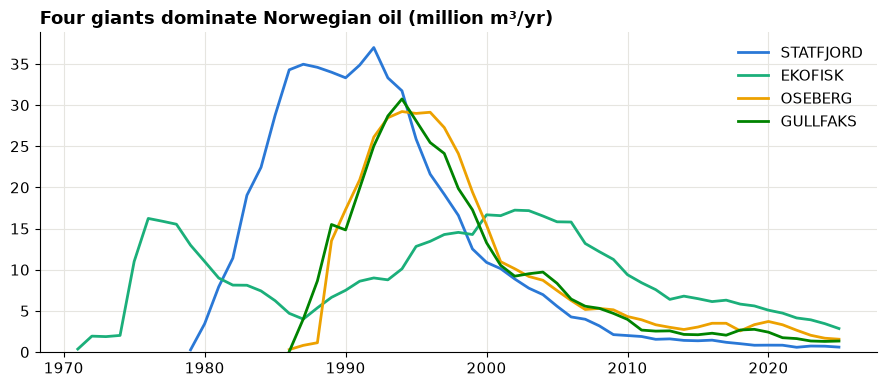

In [6]:
oil = db.production(source="sodir", product="oil")
top4 = oil.groupby("entity_name")["volume"].sum().nlargest(4).index

fig, ax = plt.subplots()
for name in top4:
    series = oil[oil["entity_name"] == name]
    yearly = (series.groupby(series["period"].dt.year)["volume"].sum() / 1e6).iloc[:-1]
    ax.plot(yearly.index, yearly.values, label=name)
ax.set_ylim(bottom=0)
ax.set_title("Four giants dominate Norwegian oil (million m³/yr)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()

## Units on demand

Everything is stored in m³; convert at the edge when you want oilfield units.

In [7]:
latest = frame[frame["period"] == frame["period"].max()]
oil_m3 = latest[latest["product"] == "oil"]["volume"].sum()
days = latest["period"].iloc[0].days_in_month
print(f"{latest['period'].iloc[0]:%B %Y}: "
      f"{ogprod.convert(oil_m3, 'm3', 'bbl') / days / 1e6:.2f} million bbl/d of oil")

July 2026: 1.78 million bbl/d of oil


## Production ⋈ entities: fields on the map

`db.entities` returns a GeoDataFrame (EPSG:4326 — Sodir fields are ring-fence
polygons) that joins production on `(source, entity_id)`. Cumulative oil per
field, straight onto the map:

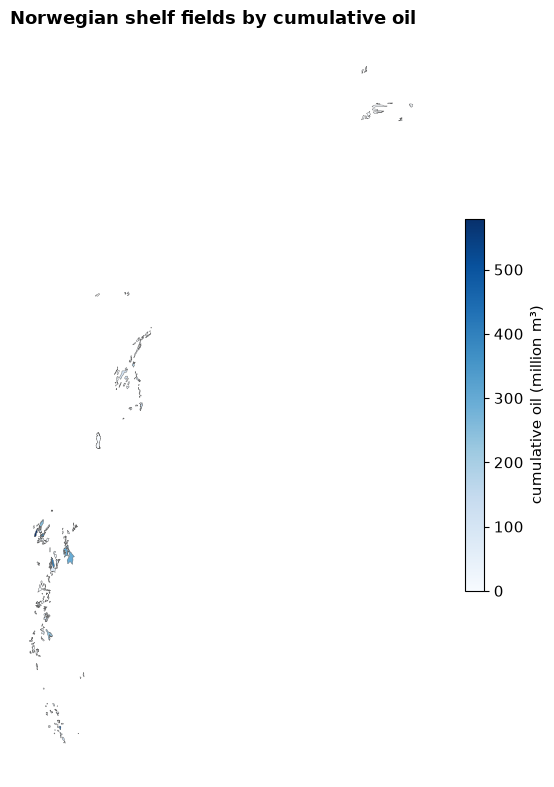

In [8]:
fields = db.entities(source="sodir")
cumulative = oil.groupby("entity_id", as_index=False)["volume"].sum()
cumulative["volume"] /= 1e6  # million m³
mapped = fields.merge(cumulative, on="entity_id", how="left")

fig, ax = plt.subplots(figsize=(7, 8))
mapped.plot(
    column="volume",
    cmap="Blues",
    edgecolor="#666666",
    linewidth=0.3,
    legend=True,
    legend_kwds={"label": "cumulative oil (million m³)", "shrink": 0.5},
    missing_kwds={"color": "#eeeeee"},
    ax=ax,
)
ax.set_title("Norwegian shelf fields by cumulative oil")
ax.set_axis_off()
fig.tight_layout()